# Midterm Project – Deep Learning
## Part 2: CNN Model – Object Recognition on CIFAR-10

---
### 1. Problem Definition
Many real-world systems need to recognise what is in a photo automatically: sorting uploaded images in photo or e-commerce apps, content moderation, wildlife camera traps, driver-assistance systems and robotics.

**Task:** multi-class image classification. Given a small colour image, predict which of 10 object categories it shows (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).

### 2. Dataset Description and Source
- **Name:** CIFAR-10
- **Source link:** https://www.cs.toronto.edu/~kriz/cifar.html (loaded here through `torchvision.datasets.CIFAR10`)
- **Size:** 60,000 colour images of 32x32 pixels: 50,000 training and 10,000 test, perfectly balanced (6,000 per class).
- **Classes:** 10 mutually exclusive classes.

### 3. Proposed Solution
A **Convolutional Neural Network** that learns visual features directly from pixels: convolution blocks extract edges, textures and shapes, pooling reduces resolution, and dense layers classify.
- Per-channel normalisation of the inputs.
- Data augmentation (random crop with padding, horizontal flip) to reduce overfitting.
- Batch Normalisation + Dropout, AdamW optimiser with a One-Cycle learning-rate schedule.
- Data split: 45,000 train / 5,000 validation / 10,000 test.

In [ ]:
import random, os, warnings
import numpy as np
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)
if device.type == "cpu":
    print("WARNING: no GPU detected. Training will be very slow. Use Runtime > Change runtime type > T4 GPU.")

### 4. Data Preprocessing
1. Pixel values are scaled to [0, 1] and normalised per channel with the CIFAR-10 training mean and standard deviation.
2. **Augmentation (training only):** random crop 32x32 with 4-pixel padding and random horizontal flip.
3. The validation and test sets get **no augmentation**, only normalisation.
4. 5,000 of the 50,000 training images are held out for validation (fixed seed).

100%|██████████| 170M/170M [00:29<00:00, 5.78MB/s]


45000 train | 5000 val | 10000 test


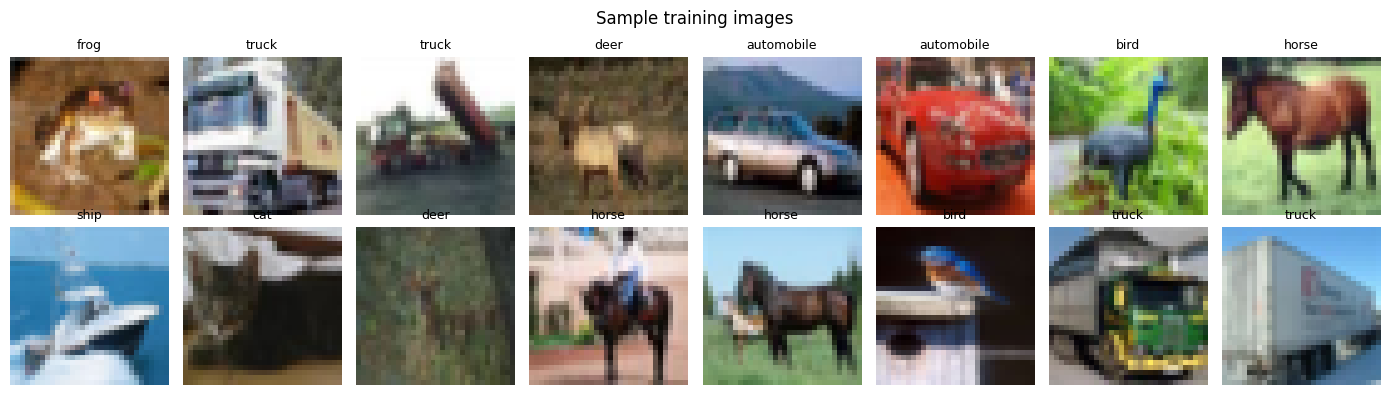

In [ ]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

root = "./data"
full_aug = torchvision.datasets.CIFAR10(root, train=True, download=True, transform=train_tf)
full_eval = torchvision.datasets.CIFAR10(root, train=True, download=False, transform=eval_tf)
test_ds = torchvision.datasets.CIFAR10(root, train=False, download=True, transform=eval_tf)

perm = torch.randperm(len(full_aug), generator=torch.Generator().manual_seed(SEED)).tolist()
train_ds = Subset(full_aug, perm[:45000])
val_ds = Subset(full_eval, perm[45000:])

BATCH = 128
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=512, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=2, pin_memory=True)
print(len(train_ds), "train |", len(val_ds), "val |", len(test_ds), "test")

# show a few raw training images
raw = torchvision.datasets.CIFAR10(root, train=True, download=False)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), range(16)):
    img, lab = raw[i]
    ax.imshow(img); ax.set_title(CLASSES[lab], fontsize=9); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout(); plt.show()

### 5. Model Architecture
Three convolution blocks (VGG-style), each with two 3x3 convolutions, followed by a small classifier.

| Stage | Output shape | Details |
|---|---|---|
| Input | 3 x 32 x 32 | normalised RGB image |
| Block 1 | 64 x 16 x 16 | 2x (Conv3x3 -> BatchNorm -> ReLU), MaxPool 2, Dropout 0.1 |
| Block 2 | 128 x 8 x 8 | 2x (Conv3x3 -> BatchNorm -> ReLU), MaxPool 2, Dropout 0.2 |
| Block 3 | 256 x 4 x 4 | 2x (Conv3x3 -> BatchNorm -> ReLU), MaxPool 2, Dropout 0.3 |
| Flatten | 4096 | |
| Dense | 256 | BatchNorm, ReLU, Dropout 0.5 |
| Output | 10 | logits; softmax gives class probabilities |

- **Loss:** cross-entropy (multi-class classification)
- **Optimizer:** AdamW (weight decay 5e-4) with a One-Cycle learning-rate schedule (max lr 3e-3)

In [ ]:
def conv_block(c_in, c_out, p):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout(p),
    )

class CifarCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 64, 0.1), conv_block(64, 128, 0.2), conv_block(128, 256, 0.3))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256), nn.BatchNorm1d(256), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = CifarCNN(num_classes=len(CLASSES)).to(device)
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(model)

Trainable parameters: 2,198,218
CifarCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-

### 6. Training

In [ ]:
EPOCHS = 25
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_loader))
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits = model(xb)
                loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state = 0.0, None
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, True)
    va_loss, va_acc = run_epoch(val_loader, False)
    for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[k].append(v)
    if va_acc > best_val_acc:
        best_val_acc = va_acc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")

model.load_state_dict(best_state)
print("Best validation accuracy:", round(best_val_acc, 4))

Epoch  1/25 | train loss 1.6272 acc 0.4058 | val loss 1.3016 acc 0.5250
Epoch  2/25 | train loss 1.1793 acc 0.5811 | val loss 0.9601 acc 0.6486
Epoch  3/25 | train loss 0.9675 acc 0.6584 | val loss 1.1428 acc 0.6074
Epoch  4/25 | train loss 0.8519 acc 0.7028 | val loss 1.0164 acc 0.6506
Epoch  5/25 | train loss 0.7816 acc 0.7267 | val loss 0.7338 acc 0.7464
Epoch  6/25 | train loss 0.7131 acc 0.7559 | val loss 0.6699 acc 0.7632
Epoch  7/25 | train loss 0.6501 acc 0.7758 | val loss 0.7576 acc 0.7376
Epoch  8/25 | train loss 0.5904 acc 0.7960 | val loss 0.5659 acc 0.8092
Epoch  9/25 | train loss 0.5463 acc 0.8142 | val loss 0.5229 acc 0.8236
Epoch 10/25 | train loss 0.5092 acc 0.8271 | val loss 0.5157 acc 0.8268
Epoch 11/25 | train loss 0.4695 acc 0.8408 | val loss 0.5185 acc 0.8180
Epoch 12/25 | train loss 0.4358 acc 0.8524 | val loss 0.4057 acc 0.8620
Epoch 13/25 | train loss 0.4107 acc 0.8602 | val loss 0.4026 acc 0.8650
Epoch 14/25 | train loss 0.3787 acc 0.8718 | val loss 0.3660 acc

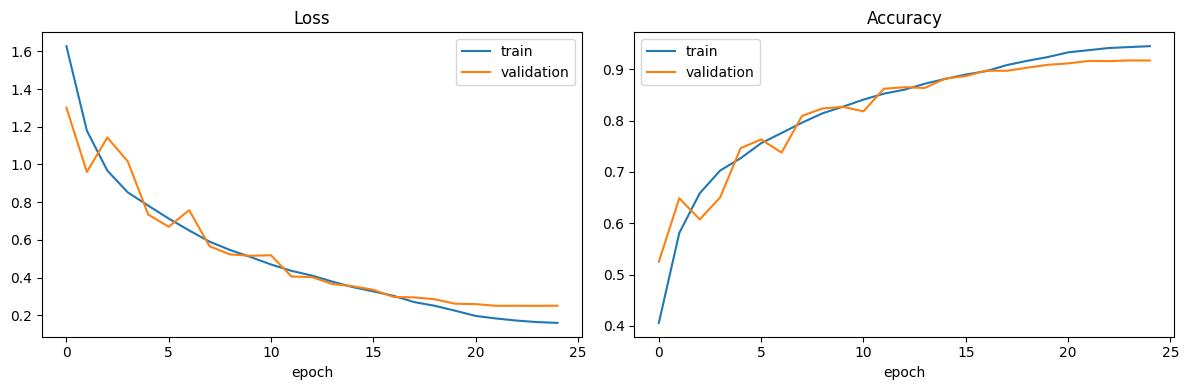

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

### 7. Evaluation on the Test Set

TEST ACCURACY: 0.9115

              precision    recall  f1-score   support

    airplane      0.912     0.919     0.915      1000
  automobile      0.948     0.969     0.958      1000
        bird      0.895     0.866     0.880      1000
         cat      0.845     0.774     0.808      1000
        deer      0.912     0.925     0.919      1000
         dog      0.834     0.889     0.861      1000
        frog      0.929     0.935     0.932      1000
       horse      0.939     0.940     0.940      1000
        ship      0.949     0.950     0.950      1000
       truck      0.951     0.948     0.949      1000

    accuracy                          0.911     10000
   macro avg      0.911     0.911     0.911     10000
weighted avg      0.911     0.911     0.911     10000



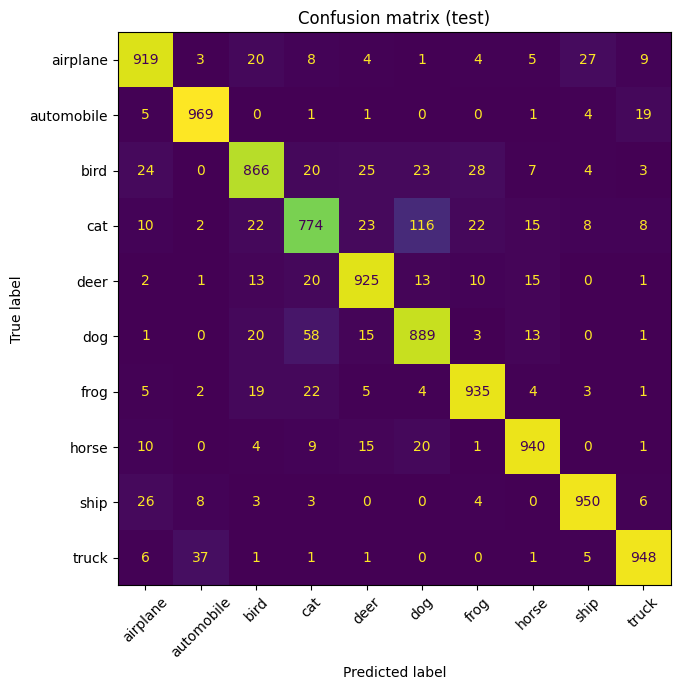

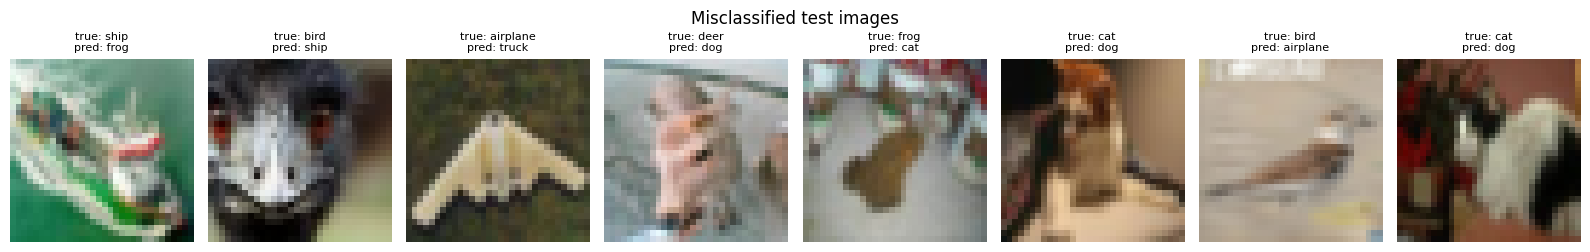

In [ ]:
@torch.no_grad()
def predict_all(loader):
    model.eval()
    preds, labels = [], []
    for xb, yb in loader:
        preds.append(model(xb.to(device)).argmax(1).cpu()); labels.append(yb)
    return torch.cat(preds).numpy(), torch.cat(labels).numpy()

y_pred, y_true = predict_all(test_loader)
test_acc = float((y_pred == y_true).mean())
print(f"TEST ACCURACY: {test_acc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("Confusion matrix (test)"); plt.tight_layout(); plt.show()

# examples of mistakes
wrong = np.where(y_pred != y_true)[0][:8]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
raw_test = torchvision.datasets.CIFAR10(root, train=False, download=False)
for ax, i in zip(axes, wrong):
    ax.imshow(raw_test[i][0]); ax.axis("off")
    ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]}", fontsize=8)
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

### 8. Save the Trained Model (`.joblib`)
The file stores the network weights, the architecture settings, the class names and the normalisation constants, so inference reproduces the exact training-time preprocessing.

In [ ]:
artifact = {
    "model_class": "CifarCNN",
    "config": {"num_classes": len(CLASSES)},
    "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
    "classes": CLASSES,
    "mean": MEAN,
    "std": STD,
    "img_size": 32,
    "test_accuracy": test_acc,
}
joblib.dump(artifact, "cifar10_cnn_model.joblib")
print("Saved cifar10_cnn_model.joblib  (%.1f MB)" % (os.path.getsize("cifar10_cnn_model.joblib") / 1e6))

Saved cifar10_cnn_model.joblib  (8.8 MB)


### 9. Inference
Load the `.joblib` file from disk, rebuild the network, and classify new images. `predict_image` accepts any PIL image (it is converted to RGB, resized to 32x32 and normalised with the saved statistics). The class `CifarCNN` defined above must exist in the session (in a fresh session, re-run the model-class cell first).

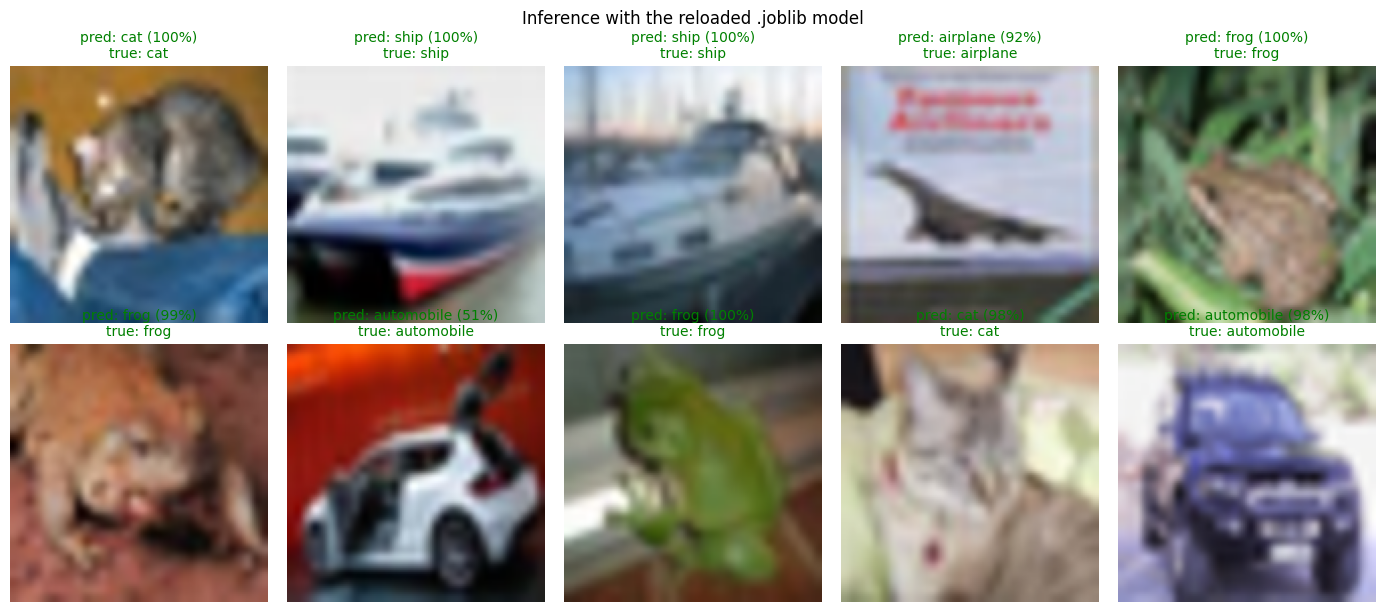

Top-3 for test image #0: [('cat', 0.9966964721679688), ('dog', 0.0032277137506753206), ('frog', 6.299420056166127e-05)]
Accuracy of reloaded model on test set: 0.9115 | in-memory: 0.9115


In [ ]:
from PIL import Image

art = joblib.load("cifar10_cnn_model.joblib")
infer_model = CifarCNN(**art["config"])
infer_model.load_state_dict(art["state_dict"])
infer_model.eval()

infer_tf = T.Compose([T.Resize((art["img_size"], art["img_size"])), T.ToTensor(), T.Normalize(art["mean"], art["std"])])

@torch.no_grad()
def predict_image(pil_img, top_k=3):
    x = infer_tf(pil_img.convert("RGB")).unsqueeze(0)
    probs = F.softmax(infer_model(x), dim=1)[0]
    conf, idx = probs.topk(top_k)
    return [(art["classes"][i], float(c)) for c, i in zip(conf, idx)]

# --- demo 1: ten unseen test images with predictions ---
fig, axes = plt.subplots(2, 5, figsize=(14, 6.2))
for ax, i in zip(axes.ravel(), range(10)):
    img, true_label = raw_test[i]
    (name, conf), *_ = predict_image(img)
    ax.imshow(img.resize((128, 128)))
    ax.set_title(f"pred: {name} ({conf:.0%})\ntrue: {CLASSES[true_label]}", fontsize=10,
                 color="green" if name == CLASSES[true_label] else "red")
    ax.axis("off")
plt.suptitle("Inference with the reloaded .joblib model"); plt.tight_layout(); plt.show()

# --- demo 2: full top-3 output for one image ---
print("Top-3 for test image #0:", predict_image(raw_test[0][0]))

# --- sanity check: reloaded model matches the in-memory model on the test set ---
infer_correct = 0
with torch.no_grad():
    for xb, yb in test_loader:
        infer_correct += (infer_model(xb).argmax(1) == yb).sum().item()
print("Accuracy of reloaded model on test set:", infer_correct / len(test_ds), "| in-memory:", test_acc)